# Version 4 — A better model: choose the strength α by cross-validation (with α = 0 allowed)

Versions 1–3 used a fixed $\alpha = 1$. That is a guess, and the earlier experiments showed it can
help on one dataset and hurt on another. Version 4 replaces the guess by **learning α inside
the training data**:

$$\alpha^{*} = \arg\max_{\alpha \in \{0,\,0.25,\,0.5,\,1,\,2\}} \; \text{CV-score}(\alpha)$$

**Why include α = 0?** At $\alpha = 0$ every correction vanishes and the output is exactly plain dropping.
Because 0 is in the search space, the chosen setting scores at least as well as plain dropping on the
*inner* cross-validated score (Theorem 1 in `docs/research_log.md`). Ties go to the smaller α, so the model
only compensates when compensation measurably helps.

`AutoAlphaSSFC` is a scikit-learn estimator: it wraps any classifier, does the PCA ranking, the
compensation and the α search inside `fit`, and can be evaluated with ordinary (outer) cross-validation, giving a
**nested, leak-free** estimate.

**Important honesty note.** The guarantee is on the *inner* CV score. On the outer (test) folds the
chosen α can still land slightly below plain dropping by chance. The summary below shows how often.

New arm in this notebook: **E. Auto-α compensation (version 4)**.

## The four results compared in every version

| Arm | What it does | Why it is there |
|---|---|---|
| **A. Naive** | all features, standardized | the baseline: what we would get if we kept everything |
| **B. PCA-guided drop** | PCA ranks features by impact; drop the *k* least impactful, **no compensation** | what a simple practitioner would do |
| **C. Compensate, then drop** | the **same** *k* features as B, but compensated into the rest first (**our idea**) | `C - B` isolates the effect of compensation |
| **D. PCA components** | classic PCA reduction to the same width (*d - k*) | standard reduction reference; loses per-feature meaning |

B and C remove exactly the same features, so any difference between them comes
from the compensation alone. Everything (PCA ranking, scaling, covariances) is
learned inside each cross-validation training fold, so nothing leaks from the test fold.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

# Make the `ssfc` package importable whether the notebook is opened from the
# repo root or from the notebooks/ folder (VS Code uses the notebook's folder).
ROOT = pathlib.Path.cwd()
if not (ROOT / "ssfc").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from ssfc import *          # SSFC, AutoAlphaSSFC, run_benchmark, paired_summary, plot_arms, ...

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: /home/claude/repo


In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

datasets = load_many(["breast_cancer", "wine", "pima", "ionosphere"])
models = {
    "LogReg": LogisticRegression(max_iter=2000),
    "RandForest": RandomForestClassifier(n_estimators=60, random_state=0, n_jobs=-1),
    "kNN(k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM-RBF": SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=0),
}

loaded breast_cancer  n=   569  d= 30  classes=2  | Breast Cancer Wisconsin (medical, binary)
loaded wine           n=   178  d= 13  classes=3  | Wine chemistry (3 classes)
loaded pima           n=   768  d=  8  classes=2  | Pima Indians Diabetes (8 features, binary)
loaded ionosphere     n=   351  d= 33  classes=2  | Ionosphere radar returns (34 features, binary)


## 1. See what the α search does on one dataset

In [3]:
X, y = datasets["pima"]
k = n_to_remove(X.shape[1], 0.25)
auto = AutoAlphaSSFC(LogisticRegression(max_iter=2000), n_remove=k, alphas=(0, 0.25, 0.5, 1, 2)).fit(X, y)
grid = pd.DataFrame(auto.cv_grid_, columns=["alpha", "beta", "inner_cv_auc"])
display(grid.round(4))
print(f"chosen alpha = {auto.best_alpha_}  (alpha = 0 means 'plain dropping was best')")

,alpha,beta,inner_cv_auc
0,0.00,1.0,0.8062
1,0.25,1.0,0.8074
2,0.50,1.0,0.8089
3,1.00,1.0,0.8117
4,2.00,1.0,0.8151


chosen alpha = 2.0  (alpha = 0 means 'plain dropping was best')


## 2. Five-arm comparison (nested CV)
`extra_arms_factory` adds arm **E** next to A–D. The α search runs inside every outer training fold.

In [4]:
FRAC_REMOVE = 0.25
N_SPLITS, N_REPEATS = 5, 2
ALPHAS, BETAS = (0.0, 0.25, 0.5, 1.0, 2.0), (1.0,)     # try BETAS=(0.5, 1.0, 2.0) for a richer (slower) search
ARM_E = "E_auto_alpha_ssfc"

def factory(model, k):
    return {ARM_E: AutoAlphaSSFC(model, n_remove=k, selection="pca_low", alphas=ALPHAS, betas=BETAS, cv=3)}

res, folds = run_benchmark(datasets, models, frac_remove=FRAC_REMOVE, alpha=1.0, beta=1.0,
                           selection="pca_low", n_splits=N_SPLITS, n_repeats=N_REPEATS,
                           extra_arms_factory=factory)
arm_table(res)

done breast_cancer LogReg                 k=8


done breast_cancer RandForest             k=8


done breast_cancer kNN(k=5)               k=8


done breast_cancer SVM-RBF                k=8


done wine          LogReg                 k=3


...

done ionosphere    LogReg                 k=8


done ionosphere    RandForest             k=8


done ionosphere    kNN(k=5)               k=8


done ionosphere    SVM-RBF                k=8


arm                      A_naive_all_features B_drop_no_compensation C_compensate_then_drop D_pca_components E_auto_alpha_ssfc
dataset       model                                                                                                           
breast_cancer LogReg          0.9948 ± 0.0050        0.9955 ± 0.0051        0.9947 ± 0.0056  0.9949 ± 0.0050   0.9956 ± 0.0051
              RandForest      0.9889 ± 0.0079        0.9894 ± 0.0084        0.9885 ± 0.0079  0.9820 ± 0.0095   0.9895 ± 0.0086
              kNN(k=5)        0.9846 ± 0.0108        0.9869 ± 0.0082        0.9837 ± 0.0083  0.9846 ± 0.0107   0.9872 ± 0.0082
              SVM-RBF         0.9949 ± 0.0053        0.9957 ± 0.0046        0.9931 ± 0.0073  0.9948 ± 0.0053   0.9957 ± 0.0046
wine          LogReg          1.0000 ± 0.0000        0.9957 ± 0.0055        0.9997 ± 0.0010  0.9997 ± 0.0008   1.0000 ± 0.0000
              RandForest      0.9993 ± 0.0017        0.9986 ± 0.0029        0.9990 ± 0.0017  0.9973 ± 0.0046   0.9967 ± 0.0041
              kNN(k=5)        0.9932 ± 0.0128        0.9834 ± 0.0151        0.9868 ± 0.0133  0.9936 ± 0.0088   0.9897 ± 0.0146
              SVM-RBF         0.9996 ± 0.0008        0.9960 ± 0.0073        0.9993 ± 0.0014  0.9996 ± 0.0008   0.9997 ± 0.0010
pima          LogReg          0.8297 ± 0.0286        0.8063 ± 0.0619        0.8081 ± 0.0524  0.8286 ± 0.0257   0.8094 ± 0.0466
              RandForest      0.8206 ± 0.0269        0.8024 ± 0.0599        0.8083 ± 0.0487  0.8006 ± 0.0286   0.8129 ± 0.0449
              kNN(k=5)        0.7741 ± 0.0207        0.7630 ± 0.0444        0.7605 ± 0.0436  0.7543 ± 0.0335   0.7648 ± 0.0356
              SVM-RBF         0.8225 ± 0.0256        0.8007 ± 0.0511        0.8042 ± 0.0471  0.8173 ± 0.0271   0.8042 ± 0.0440
ionosphere    LogReg          0.9012 ± 0.0504        0.9095 ± 0.0365        0.9138 ± 0.0383  0.9173 ± 0.0459   0.9116 ± 0.0327
              RandForest      0.9791 ± 0.0138        0.9757 ± 0.0169        0.9736 ± 0.0149  0.9764 ± 0.0162   0.9733 ± 0.0160
              kNN(k=5)        0.9134 ± 0.0390        0.9117 ± 0.0242        0.8837 ± 0.0455  0.9160 ± 0.0302   0.9126 ± 0.0240
              SVM-RBF         0.9797 ± 0.0180        0.9782 ± 0.0207        0.9567 ± 0.0264  0.9761 ± 0.0195   0.9782 ± 0.0207

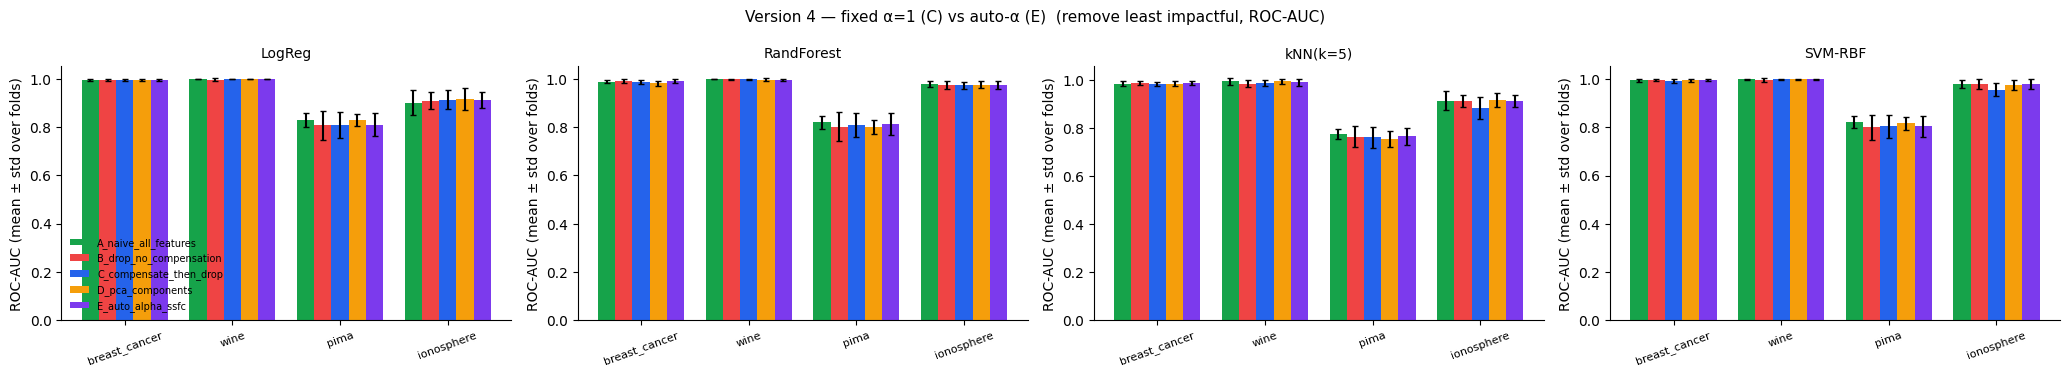

In [5]:
plot_arms(res, title="Version 4 — fixed α=1 (C) vs auto-α (E)  (remove least impactful, ROC-AUC)")
plt.show()

### Paired summary against plain drop (B)
`comp_minus_drop` = fixed α = 1 (version 1–3 behaviour). `extra_minus_drop` = auto-α (version 4).

In [6]:
summ = paired_summary(res, folds, extra_arm=ARM_E)
display(summ[["dataset", "model", "auc_drop", "auc_comp", "auc_extra", "comp_minus_drop", "se",
              "extra_minus_drop", "extra_se"]].round(4))
v_fixed = verdict_counts(summ, "comp_minus_drop", "se")
v_auto = verdict_counts(summ, "extra_minus_drop", "extra_se")
print("fixed α=1 vs drop :", v_fixed)
print("auto-α   vs drop :", v_auto)
print(f"\nworst case  fixed α=1: {summ.comp_minus_drop.min():+.4f}    auto-α: {summ.extra_minus_drop.min():+.4f}")
print(f"best  case  fixed α=1: {summ.comp_minus_drop.max():+.4f}    auto-α: {summ.extra_minus_drop.max():+.4f}")

,dataset,model,auc_drop,auc_comp,auc_extra,comp_minus_drop,se,extra_minus_drop,extra_se
0,breast_cancer,LogReg,0.9955,0.9947,0.9956,-0.0008,0.0002,0.0000,0.0000
1,breast_cancer,RandForest,0.9894,0.9885,0.9895,-0.0010,0.0022,0.0001,0.0005
2,breast_cancer,kNN(k=5),0.9869,0.9837,0.9872,-0.0032,0.0021,0.0003,0.0015
3,breast_cancer,SVM-RBF,0.9957,0.9931,0.9957,-0.0026,0.0011,0.0000,0.0000
4,wine,LogReg,0.9957,0.9997,1.0000,0.0040,0.0016,0.0043,0.0018
5,wine,RandForest,0.9986,0.9990,0.9967,0.0004,0.0006,-0.0019,0.0015
6,wine,kNN(k=5),0.9834,0.9868,0.9897,0.0034,0.0022,0.0063,0.0044
7,wine,SVM-RBF,0.9960,0.9993,0.9997,0.0033,0.0020,0.0036,0.0022
8,pima,LogReg,0.8063,0.8081,0.8094,0.0018,0.0038,0.0032,0.0076
9,pima,RandForest,0.8024,0.8083,0.8129,0.0059,0.0078,0.0106,0.0069


fixed α=1 vs drop : {'better': 5, 'within_noise': 6, 'worse': 5, 'total': 16}
auto-α   vs drop : {'better': 5, 'within_noise': 9, 'worse': 2, 'total': 16}

worst case  fixed α=1: -0.0280    auto-α: -0.0024
best  case  fixed α=1: +0.0059    auto-α: +0.0106


## 3. Which α does the search pick?
Fit on each full dataset (for illustration; inside CV it is re-chosen per fold).

In [7]:
rows = []
for dname, (X, y) in datasets.items():
    k = n_to_remove(X.shape[1], FRAC_REMOVE)
    for mname, model in models.items():
        a = AutoAlphaSSFC(model, n_remove=k, alphas=ALPHAS, betas=BETAS, cv=3).fit(X, y)
        rows.append(dict(dataset=dname, model=mname, chosen_alpha=a.best_alpha_,
                         inner_cv_auc_alpha0=a.cv_grid_[0][2], inner_cv_auc_chosen=a.best_cv_score_))
chosen = pd.DataFrame(rows)
display(chosen.round(4))
print("\nshare of cases where the search chose alpha = 0 (plain dropping):",
      f"{(chosen.chosen_alpha == 0).mean():.0%}")

,dataset,model,chosen_alpha,inner_cv_auc_alpha0,inner_cv_auc_chosen
0,breast_cancer,LogReg,0.00,0.9953,0.9953
1,breast_cancer,RandForest,0.00,0.9882,0.9882
2,breast_cancer,kNN(k=5),0.50,0.9788,0.9810
3,breast_cancer,SVM-RBF,0.00,0.9950,0.9950
4,wine,LogReg,0.50,0.9991,0.9997
5,wine,RandForest,0.25,0.9990,0.9993
6,wine,kNN(k=5),1.00,0.9977,0.9984
7,wine,SVM-RBF,1.00,0.9992,0.9996
8,pima,LogReg,2.00,0.8062,0.8151
9,pima,RandForest,2.00,0.7957,0.8128



share of cases where the search chose alpha = 0 (plain dropping): 31%


**Reading the chosen α.** If the search picks the *largest* value in the grid (it does for some Pima rows), the grid is too
narrow: extend `ALPHAS` (for example add 4 and 8) and re-run. Very large α with many removed, correlated features can also inflate the
scale of the kept columns (see the scale check in version 3), so look at the inner-CV scores, not only the chosen value.

## 4. Stress test: remove the MOST impactful features (PCA)

In [8]:
def factory_h(model, k):
    return {ARM_E: AutoAlphaSSFC(model, n_remove=k, selection="pca_high", alphas=ALPHAS, betas=BETAS, cv=3)}

res_h, folds_h = run_benchmark(datasets, models, frac_remove=FRAC_REMOVE, alpha=1.0, beta=1.0,
                               selection="pca_high", n_splits=N_SPLITS, n_repeats=N_REPEATS,
                               extra_arms_factory=factory_h, verbose=False)
summ_h = paired_summary(res_h, folds_h, extra_arm=ARM_E)
display(summ_h[["dataset", "model", "auc_naive", "auc_drop", "auc_comp", "auc_extra", "comp_minus_drop",
                "extra_minus_drop", "extra_se"]].round(4))
print("fixed α=1 vs drop:", verdict_counts(summ_h, "comp_minus_drop", "se"))
print("auto-α   vs drop:", verdict_counts(summ_h, "extra_minus_drop", "extra_se"))

,dataset,model,auc_naive,auc_drop,auc_comp,auc_extra,comp_minus_drop,extra_minus_drop,extra_se
0,breast_cancer,LogReg,0.9948,0.9917,0.9933,0.9930,0.0017,0.0014,0.0014
1,breast_cancer,RandForest,0.9889,0.9905,0.9897,0.9917,-0.0008,0.0011,0.0009
2,breast_cancer,kNN(k=5),0.9846,0.9784,0.9774,0.9869,-0.0010,0.0085,0.0041
3,breast_cancer,SVM-RBF,0.9949,0.9935,0.9832,0.9942,-0.0102,0.0007,0.0007
4,wine,LogReg,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000
5,wine,RandForest,0.9993,0.9993,0.9970,0.9983,-0.0023,-0.0010,0.0009
6,wine,kNN(k=5),0.9932,0.9977,0.9952,0.9975,-0.0024,-0.0002,0.0002
7,wine,SVM-RBF,0.9996,0.9999,0.9999,0.9999,0.0000,0.0000,0.0000
8,pima,LogReg,0.8297,0.8214,0.8231,0.8228,0.0017,0.0014,0.0015
9,pima,RandForest,0.8206,0.8054,0.8177,0.8129,0.0123,0.0076,0.0033


fixed α=1 vs drop: {'better': 3, 'within_noise': 7, 'worse': 6, 'total': 16}
auto-α   vs drop: {'better': 5, 'within_noise': 7, 'worse': 4, 'total': 16}


In [9]:
pd.concat([res.assign(experiment="remove_least_impactful"),
           res_h.assign(experiment="remove_most_impactful")]).to_csv(RESULTS / "v4_results.csv", index=False)
chosen.to_csv(RESULTS / "v4_chosen_alpha.csv", index=False)
print("saved results/v4_results.csv and results/v4_chosen_alpha.csv")

saved results/v4_results.csv and results/v4_chosen_alpha.csv


## 5. What version 4 does and does not give you

**Gives you**
* No hand-tuned α: the data decide, and "do not compensate" (α = 0) is always an option.
* A provable inner-CV guarantee against plain dropping (Theorem 1), and a nested outer-CV
  estimate of the real behaviour.

**Does not give you**
* A guarantee on future test data; it is a cross-validation guarantee, like any tuned hyper-parameter.
* Gains when there is nothing to recover: if the removed features carry little signal, the search often
  picks α = 0 and E ≈ B. That is the method working as intended.
* Non-linear compensation: the injected term is linear in the removed feature's covariance.
* A missing-data solution: removed features must still be measured to compute the gate.

**Ideas for a version 5:** non-linear (kernel / learned) compensation, supervised feature selection instead of
PCA impact, per-feature α, regression targets, and many more datasets.